# 10.2.1 Dois trechos de dutos em série

Dois dutos de 500 m (25 elementos cada), cenário de 10.1.1, diferenças finitas centrais.
Formulação A: trechos ligados por especificação de **conexão** (pressão do vértice a montante =
pressão do 1.º nó do trecho a jusante; vazões do vértice a jusante = vazões do último nó do
trecho a montante). Formulação B: trechos acoplados por **vértice dinâmico** (tipo A).
Figuras 10.20 a 10.24 e Tabelas 10.2 e 10.3.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thesis.notebook_utils import thesis_run, compare_states, show_pipe, plot_elements, plot_vertices
from thesis.mf2 import legacy_pipe_dict
from mfsim.plotting import pipe_profiles, compare_runs
from mfsim.runs import load_run

runA, resA, rawA = thesis_run("10.2.1A")
compare_states(resA, rawA)
runB, resB, rawB = thesis_run("10.2.1B")
compare_states(resB, rawB)

10.2.1 Dois trechos em série (formulação A: conexão)
Dois dutos de 500 m (25 elementos cada) ligados por especificação de conexão; cenário de 10.1.1; diferenças finitas centrais.
Figuras da tese: Figs. 10.20-10.24, Tabelas 10.2-10.3
corrida 10_2_1A.npz: integrador bdf (rtol 0.001, atol 0.001, max_step 1.0), 301 instantes de saída até 3000 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 twofluid     alphaG    1.67e-05       5.47e-02   3.05e-04
   1 twofluid     PT        1.87e-06       5.57e-04   3.35e-03
   1 twofluid     qL        4.63e-04       1.46e-01   3.17e-03
   1 twofluid     qG        1.34e-04       2.99e-02   4.48e-03
   2 twofluid     alphaG    4.41e-06       2.94e-02   1.50e-04
   2 twofluid     PT        1.25e-06       4.14e-04   3.03e-03
   2 twofluid     qL        4.73e-04       1.46e-01   3.24e-03
   2 twofluid     qG        9.06e-05       2.51e-02   3.61e-03
10.2.1 Dois trechos em série (formulação B: vértice dinâmico)
Dois dutos de 500 m acoplado

## Figuras 10.20 a 10.23: fração de gás, pressão e vazões nos dois trechos (formulação A)

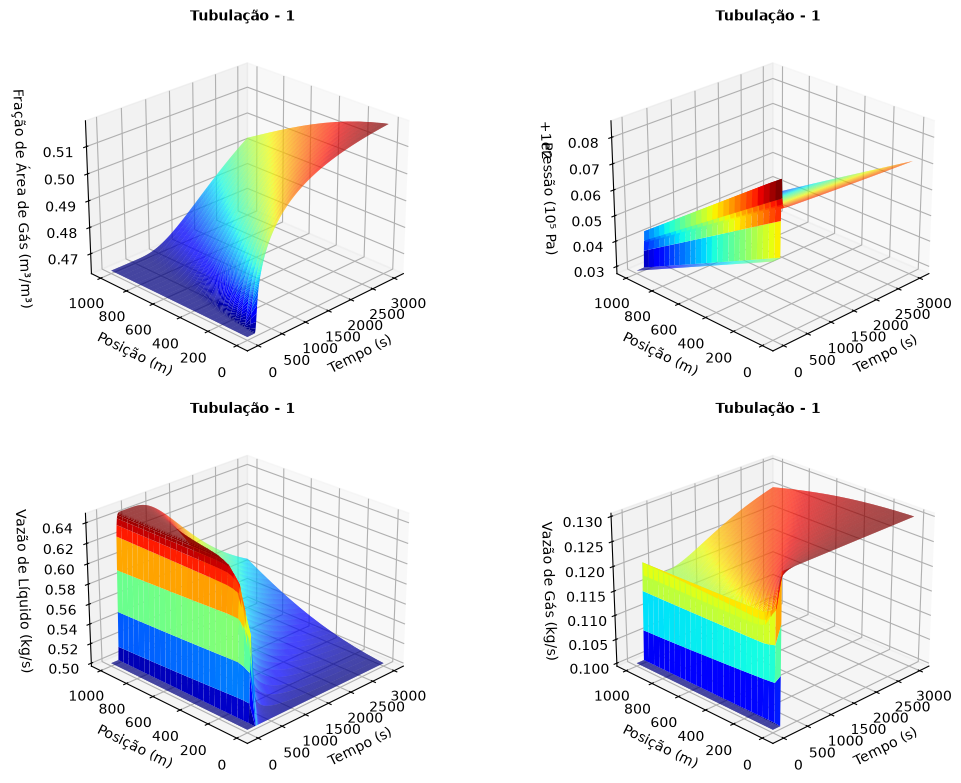

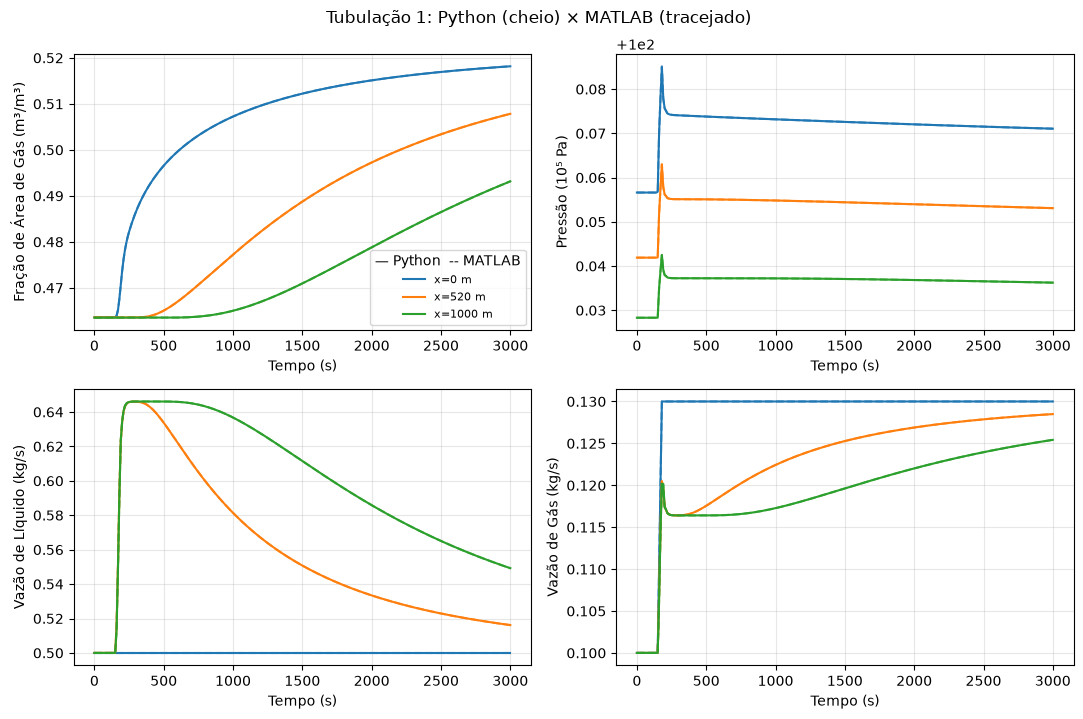

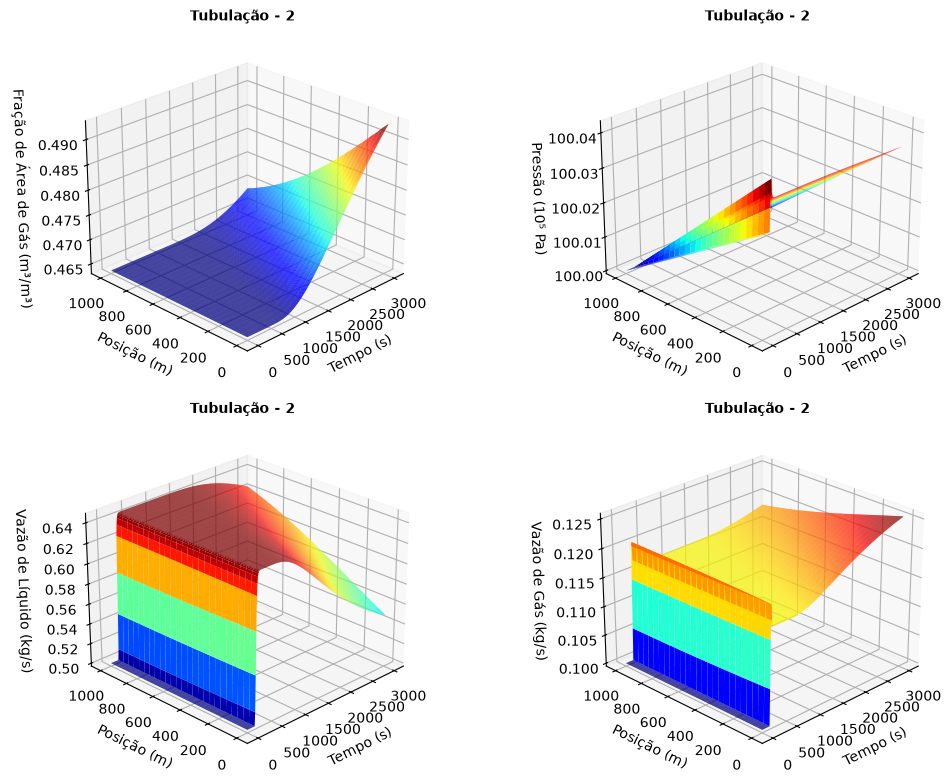

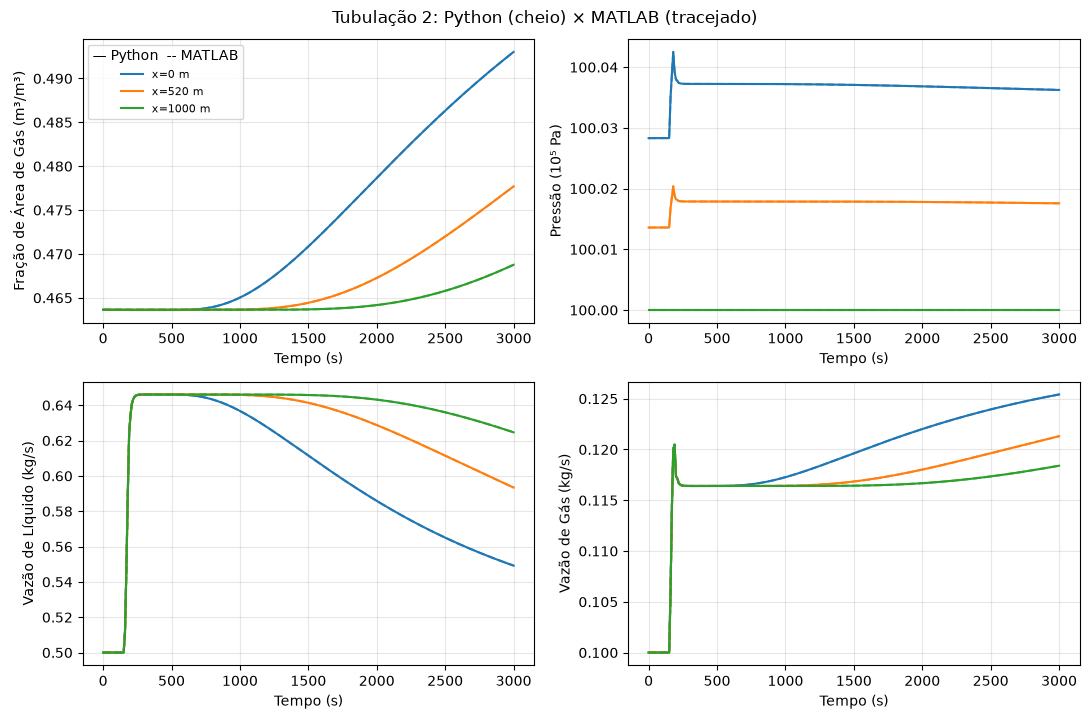

In [2]:
for k in (0, 1):
    show_pipe(resA, rawA, k)

## Formulação A × formulação B (saída do trecho 2)

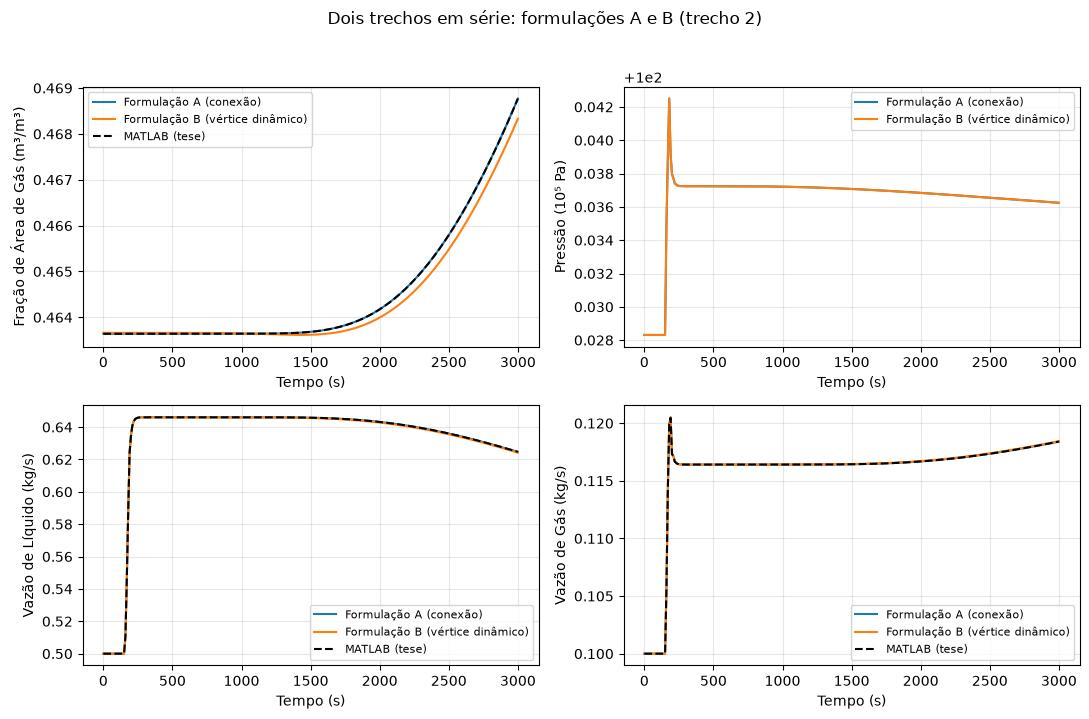

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, k_ in zip(axes.ravel(), ["alphaG", "P_bar", "qL", "qG"]):
    compare_runs(
        {"Formulação A (conexão)": resA, "Formulação B (vértice dinâmico)": resB},
        k=1,
        key=k_,
        node=-1 if k_ != "P_bar" else 0,
        ax=ax,
        legacy=legacy_pipe_dict(rawA, 1) if k_ != "P_bar" else None,
    )
fig.suptitle("Dois trechos em série: formulações A e B (trecho 2)", y=1.02)
fig.tight_layout()
plt.show()

## Balanço de massa no vértice de acoplamento (Figura 10.24, Tabela 10.3)

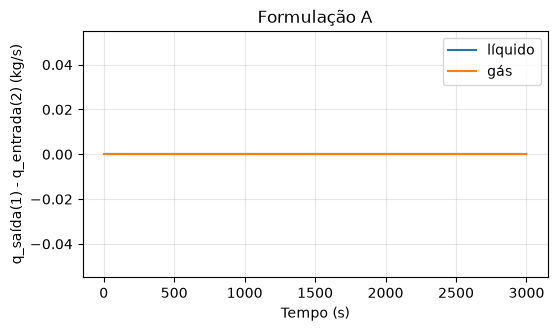

Formulação A - Tabela 10.3
 t (s)  qL saída 1  qL entrada 2  qG saída 1  qG entrada 2
     0       0.500         0.500       0.100         0.100
   750       0.644         0.644       0.117         0.117
  1000       0.637         0.637       0.117         0.117
  2000       0.586         0.586       0.122         0.122
  3000       0.549         0.549       0.125         0.125


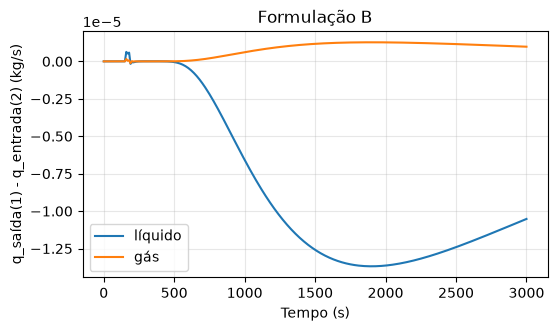

Formulação B - Tabela 10.3
 t (s)  qL saída 1  qL entrada 2  qG saída 1  qG entrada 2
     0       0.500         0.500       0.100         0.100
   750       0.644         0.644       0.117         0.117
  1000       0.637         0.637       0.117         0.117
  2000       0.586         0.586       0.122         0.122
  3000       0.549         0.549       0.125         0.125


In [4]:
for label, res in (("A", resA), ("B", resB)):
    p1, p2 = res.pipe(0), res.pipe(1)
    dL = p1["out"]["qL"][-1] - p2["out"]["qL"][0]
    dG = p1["out"]["qG"][-1] - p2["out"]["qG"][0]
    fig, ax = plt.subplots(figsize=(6, 3.2))
    ax.plot(res.T, dL, label="líquido")
    ax.plot(res.T, dG, label="gás")
    ax.set_xlabel("Tempo (s)")
    ax.set_ylabel("q_saída(1) - q_entrada(2) (kg/s)")
    ax.set_title(f"Formulação {label}")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()
    print(f"Formulação {label} - Tabela 10.3")
    print(f"{'t (s)':>6s} {'qL saída 1':>11s} {'qL entrada 2':>13s} {'qG saída 1':>11s} {'qG entrada 2':>13s}")
    for t in (0, 750, 1000, 2000, 3000):
        it = int(np.argmin(np.abs(res.T - t)))
        print(
            f"{res.T[it]:6.0f} {p1['out']['qL'][-1, it]:11.3f} {p2['out']['qL'][0, it]:13.3f} {p1['out']['qG'][-1, it]:11.3f} {p2['out']['qG'][0, it]:13.3f}"
        )

---
*Notebook de reprodução fiel: nenhuma simulação corre aqui. As corridas vêm do lote
`batches/thesis.json` (`uv run mfsim batch batches/thesis.json`), com a configuração exportada
do ficheiro original; as correções e melhorias estão nos notebooks de `notebooks_src/issues/`
e no índice [docs/issues/INDEX.md](../../docs/issues/INDEX.md).*